In [ ]:
# connect drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# import libraries
from pathlib import Path
import json

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import matplotlib.pyplot as plt

import pandas as pd
import numpy as np

In [ ]:
%cd /content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation/notebooks

/content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation/notebooks


In [ ]:
Path.cwd()

PosixPath('/content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation/notebooks')

In [ ]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

print("project root:", PROJECT_ROOT)
print("data dir:", DATA_DIR)
print("processed dir:", PROCESSED_DIR)

project root: /content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation
data dir: /content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation/data
processed dir: /content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation/data/processed


In [ ]:
# load saved tensors
data = torch.load(
    PROCESSED_DIR / "translation_ids.pt",
    map_location=torch.device("cpu"),
    weights_only=True,
)

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]


In [ ]:

from tokenizers import Tokenizer

english_tokenizer = Tokenizer.from_file(
    str(PROCESSED_DIR / "english_tokenizer.json")
)

french_tokenizer = Tokenizer.from_file(
    str(PROCESSED_DIR / "french_tokenizer.json")
)

with open(PROCESSED_DIR / "preprocessing_config.json", "r") as file:
    config = json.load(file)


In [ ]:

EN_VOCAB_SIZE = english_tokenizer.get_vocab_size()
FR_VOCAB_SIZE = french_tokenizer.get_vocab_size()

PAD_ID = french_tokenizer.token_to_id("[PAD]")
BOS_ID = french_tokenizer.token_to_id("[BOS]")
EOS_ID = french_tokenizer.token_to_id("[EOS]")

print("Training tensors:", X_train.shape, y_train.shape)
print("Validation tensors:", X_val.shape, y_val.shape)
print("Test tensors:", X_test.shape, y_test.shape)

print("\nEnglish vocabulary size:", EN_VOCAB_SIZE)
print("French vocabulary size:", FR_VOCAB_SIZE)

print("\nFrench special-token IDs:")
print("PAD:", PAD_ID)
print("BOS:", BOS_ID)
print("EOS:", EOS_ID)

print("\nPreprocessing configuration:")
print(config)


Training tensors: torch.Size([133704, 20]) torch.Size([133704, 22])
Validation tensors: torch.Size([16713, 20]) torch.Size([16713, 22])
Test tensors: torch.Size([16713, 20]) torch.Size([16713, 22])

English vocabulary size: 14493
French vocabulary size: 23539

French special-token IDs:
PAD: 1
BOS: 2
EOS: 3

Preprocessing configuration:
{'english_max_length': 20, 'french_max_length': 22, 'english_vocab_size': 14493, 'french_vocab_size': 23539, 'pad_token': '[PAD]', 'unk_token': '[UNK]', 'bos_token': '[BOS]', 'eos_token': '[EOS]'}


In [ ]:
EN_VOCAB_SIZE = english_tokenizer.get_vocab_size()
EN_PAD_ID = english_tokenizer.token_to_id("[PAD]")

FR_VOCAB_SIZE = french_tokenizer.get_vocab_size()
FR_PAD_ID = french_tokenizer.token_to_id("[PAD]")

print("English vocabulary:", EN_VOCAB_SIZE)
print("English padding ID:", EN_PAD_ID)
print("French vocabulary:", FR_VOCAB_SIZE)
print("French padding ID:", FR_PAD_ID)

English vocabulary: 14493
English padding ID: 1
French vocabulary: 23539
French padding ID: 1


In [ ]:
# encoder class

class Encoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_layers,
        padding_idx
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx,
        )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
            )

        packed_outputs, hidden = self.gru(packed)

        outputs, _ = nn.utils.rnn.pad_packed_sequence(
            packed_outputs, batch_first=True,
            total_length=input_ids.shape[1]
        )

        return outputs, hidden


In [ ]:
train_en_lengths = (X_train != EN_PAD_ID).sum(dim=1)
val_en_lengths = (X_val != EN_PAD_ID).sum(dim=1)
test_en_lengths = (X_test != EN_PAD_ID).sum(dim=1)

print("First 5 English lengths:", train_en_lengths[:5])
print("First 5 English sequences:", X_train[:5].shape)

First 5 English lengths: tensor([ 8, 16, 11, 11,  9])
First 5 English sequences: torch.Size([5, 20])


In [ ]:
encoder = Encoder(
    vocab_size=EN_VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=256,
    num_layers=1,
    padding_idx=EN_PAD_ID,
)

outputs, hidden = encoder(
    X_train[:4],
    train_en_lengths[:4],
)

print("Encoder outputs:", outputs.shape)
print("Encoder hidden state:", hidden.shape)

Encoder outputs: torch.Size([4, 20, 256])
Encoder hidden state: torch.Size([1, 4, 256])


In [ ]:
# Decoder class

class Decoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_layers,
        padding_idx,
        dropout_rate=0.2
    ):
        super().__init__()

        # convert French token IDs into vectors
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx,
        )

        # process the French sequence
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,

        )

        # Dropout before the output projection
        self.dropout = nn.Dropout(dropout_rate)

        # convert each GRU output into vocabulary scores
        self.fc = nn.Linear(
            in_features=hidden_dim,
            out_features=vocab_size,
        )

    def forward(self, input_ids, hidden):
        # (batch_size, target_length)
        embedded = self.embedding(input_ids)

        # (batch_size, target_length, embedding_dim)
        outputs, hidden = self.gru(embedded, hidden)

        # Apply dropout to GRU outputs
        outputs = self.dropout(outputs)

        # (batch_size, target_length, vocab_size)
        logits = self.fc(outputs)

        return logits, hidden



In [ ]:
# Seq2Seq class


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, source_ids, source_lengths, target_ids):
        # Encode the English sentences
        encoder_outputs, encoder_hidden = self.encoder(
            source_ids,
            source_lengths,
        )

        # Use the encoder's final hidden state to initialize the decoder
        logits, decoder_hidden = self.decoder(
            target_ids,
            encoder_hidden,
        )

        return logits


In [ ]:

encoder = Encoder(
    vocab_size=EN_VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=256,
    num_layers=1,
    padding_idx=EN_PAD_ID,
)

decoder = Decoder(
    vocab_size=FR_VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=256,
    num_layers=1,
    padding_idx=FR_PAD_ID,
    dropout_rate=0.2,
)

model = Seq2Seq(
    encoder=encoder,
    decoder=decoder,
)


In [ ]:

source_ids = X_train[:4]
source_lengths = train_en_lengths[:4]

decoder_input = y_train[:4, :-1]

logits = model(
    source_ids,
    source_lengths,
    decoder_input,
)

print("Decoder input:", decoder_input.shape)
print("Model logits:", logits.shape)


Decoder input: torch.Size([4, 21])
Model logits: torch.Size([4, 21, 23539])


In [ ]:
# switch to device to cuda

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
%%writefile -a utils.py
# training and evaluation function
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm import tqdm

def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    scheduler,
    num_epochs,
    EN_PAD_ID,
    FR_PAD_ID,
    device
):
    model.to(device)

    train_losses = [],
    val_losses = [],

    train_accuracies = [],
    val_accuracies = [],
    learning_rates = [],

    #--------------------------------
    # Training
    #--------------------------------

    for epoch in range(num_epochs):
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for source_ids, target_ids in train_loader:


            source_ids = source_ids.to(device)
            target_ids = target_ids.to(device)


            decoder_input = target_ids[:, :-1]
            expected = target_ids[:, 1:]
            source_lengths = (source_ids != EN_PAD_ID).sum(dim=1)

            optimizer.zero_grad()

            logits = model(
                source_ids,
                source_lengths,
                decoder_input,
            )

            loss = criterion(logits.transpose(1, 2), expected)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()

            valid = expected != FR_PAD_ID
            train_loss += loss.item() * valid.sum().item()
            train_correct += (
                (logits.argmax(dim=-1) == expected) & valid
                ).sum().item()

            train_total = valid.sum().item()


        train_losses.append(train_loss / train_total)
        train_accuracies.append(train_correct / train_total)

        # ---------------------------------------------------
        # Validation
        #----------------------------------------------------
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for source_ids, target_ids in val_loader:
                source_ids = source_ids.to(device)
                target_ids = target_ids.to(device)

                source_lengths = (source_ids != EN_PAD_ID).sum(dim=1)

                decoder_input = target_ids[:, :-1]
                expected = target_ids[:, 1:]

                logits = model(
                    source_ids,
                    source_lengths,
                    decoder_input,
                )

                loss = criterion(logits.transpose(1, 2), expected)

                valid = expected != FR_PAD_ID
                val_loss += loss.item() * valid.sum().item()
                val_correct += (
                    (logits.argmax(dim=-1) == expected) & valid
                    ).sum().item()
                val_total = valid.sum().item()

        val_losses.append(val_loss / val_total)
        val_accuracies.append(val_correct / val_total)

        # ----------------------------------------------
        # Learning rate schedule
        # ----------------------------------------------

        scheduler.step(val_losses[-1])
        learning_rates.append(optimizer.param_groups[0]["lr"])

        print(
            f"Epoch [{epoch + 1}/{num_epochs}] "
            f"Train Loss: {train_losses[-1]:.4f} | "
            f"Val Loss: {val_losses[-1]:.4f} | "
            f"Train Acc: {train_accuracies[-1]:.4f} | "
            f"Val Acc: {val_accuracies[-1]:.4f} | "
            f"LR: {learning_rates[-1]:.6f}"
        )

    return {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accuracies": train_accuracies,
        "val_accuracies": val_accuracies,
        "learning_rates": learning_rates,
    }





Appending to utils.py


In [ ]:
%%writefile -a utils.py
# plotting function
import matplotlib.pyplot as plt

def plot_training_history(history):
    epochs = range(1, len(history["train_losses"]) + 1)

     # 1. Loss
    plt.figure(figsize=(12, 5))
    plt.plot(epochs, history["train_losses"], label="Training Loss")
    plt.plot(epochs, history["val_losses"], label="Validation Loss")
    plt.title("Training and Validation Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    # 2. Acurracy
    plt.figure(figsize=(12, 5))
    plt.plot(epochs, history["train_accuracies"], label="Training Accuracy")
    plt.plot(epochs, history["val_accuracies"], label="Validation Accuracy")
    plt.title("Training and Validation Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    # 3. Learning rate
    plt.figure(figsize=(12, 5))
    plt.plot(epochs, history["learning_rates"], label="Learning Rate")
    plt.title("Learning Rate Schedule")
    plt.xlabel("Epochs")
    plt.ylabel("Learning Rate")
    plt.legend()
    plt.grid(True)
    plt.yscale("log")
    plt.show()

#

Appending to utils.py


In [ ]:
%%writefile -a utils.py
def evaluate_model(
    model,
    test_loader,
    criterion,
    device,
    en_pad_id,
    fr_pad_id,
):
    """
    Evaluate a trained Seq2Seq model on the test dataset.

    Returns:
        Dictionary containing test loss and token accuracy.
    """

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_tokens = 0

    with torch.no_grad():

        for source_ids, target_ids in test_loader:

            source_ids = source_ids.to(device)
            target_ids = target_ids.to(device)

            # Calculate the actual English sequence lengths.
            source_lengths = (source_ids != en_pad_id).sum(dim=1)

            # Teacher forcing: shift the French target by one position.
            decoder_input = target_ids[:, :-1]
            expected = target_ids[:, 1:]

            # Forward pass.
            logits = model(
                source_ids,
                source_lengths,
                decoder_input,
            )

            # Count only non-padding target tokens.
            valid_tokens = expected != fr_pad_id
            num_tokens = valid_tokens.sum().item()

            # CrossEntropyLoss expects (batch, classes, sequence).
            loss = criterion(
                logits.transpose(1, 2),
                expected,
            )

            total_loss += loss.item() * num_tokens

            # Get the predicted token at each position.
            predictions = logits.argmax(dim=-1)

            # Ignore padding when calculating accuracy.
            correct = (
                (predictions == expected) & valid_tokens
            ).sum().item()

            total_correct += correct
            total_tokens += num_tokens

    test_loss = total_loss / total_tokens
    test_accuracy = total_correct / total_tokens

    results = {
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
    }

    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Token Accuracy: {test_accuracy:.2%}")

    return results


Appending to utils.py


In [ ]:
# create tensor dataset and dataloader

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [ ]:
print(len(train_loader))
print(len(val_loader))
print(len(test_loader))

2090
262
262


# GRU Baseline Model (E0)

The baseline is a sequence-to-sequence model for English-to-French translation using a GRU encoder and GRU decoder without attention.

## Architecture Configuration

- Encoder GRU layers: 1
- Decoder GRU layers: 1
- English embedding dimension: 128
- French embedding dimension: 128
- Hidden dimension: 256
- Dropout: 0.2

## Training Configuration

- Optimizer: Adam
- Initial learning rate: 0.001
- Weight decay: 0.00001
- Loss function: Cross-entropy, ignoring French padding tokens
- Gradient clipping: Maximum norm of 1.0
- Learning-rate scheduler: ReduceLROnPlateau
- Batch size: 64
- Maximum epochs: 20

## Objective

Establish baseline performance using validation loss and token accuracy. This model will serve as the reference for subsequent experiments investigating GRU depth and embedding dimension while keeping other settings constant.

In [ ]:

# Baseline GRU configuration: E0

BASELINE_CONFIG = {
    "embedding_dim": 128,
    "hidden_dim": 256,
    "num_layers": 1,
    "dropout_rate": 0.2,
    "batch_size": 64,
    "learning_rate": 0.001,
    "weight_decay": 1e-5,
    "num_epochs": 20,
    "gradient_clip": 1.0,
}


In [ ]:
# Baseline GRU model parameters
EMBEDDING_DIM = 128
HIDDEN_DIM = 256
NUM_LAYERS = 1
DROPOUT_RATE = 0.2

# Training parameters
BATCH_SIZE = 64
NUM_EPOCHS = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
GRADIENT_CLIP = 1.0

# Learning-rate scheduler parameters
SCHEDULER_FACTOR = 0.8
SCHEDULER_PATIENCE = 3
MIN_LEARNING_RATE = 1e-6

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")

Device: cuda


In [ ]:
# 1. Initialize the encoder
encoder = Encoder(
    vocab_size=EN_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=EN_PAD_ID,
)

# 2. Initialize the decoder
decoder = Decoder(
    vocab_size=FR_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=FR_PAD_ID
)

In [ ]:
# Combine encoder and decoder
model = Seq2Seq(
    encoder=encoder,
    decoder=decoder
).to(device=device)

# Initialize the loss function
criterion = nn.CrossEntropyLoss(
    ignore_index=FR_PAD_ID,
)

# Initialize the optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

# Initialize the learnining rate schedular
sheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=SCHEDULER_FACTOR,
    patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LEARNING_RATE,
)

print(f"Device: {device}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Device: cuda
Trainable parameters: 11,510,515


In [ ]:
# Get one batch
source_ids, target_ids = next(iter(train_loader))

source_ids = source_ids.to(device)
target_ids = target_ids.to(device)

# Calculate English sequence lengths
source_lengths = (source_ids != EN_PAD_ID).sum(dim=1)

# Prepare decoder input using teacher forcing
decoder_input = target_ids[:, :-1]

# Test the forward pass
model.eval()

with torch.no_grad():
    logits = model(
        source_ids,
        source_lengths,
        decoder_input,
    )

print("Source shape:", source_ids.shape)
print("Decoder input shape:", decoder_input.shape)
print("Logits shape:", logits.shape)

Source shape: torch.Size([64, 20])
Decoder input shape: torch.Size([64, 21])
Logits shape: torch.Size([64, 21, 23539])


In [ ]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

print(PROJECT_ROOT)

/content/drive/MyDrive/english-french-machine-translation/english-french-machine-translation


In [ ]:
sys.path.insert(0, str(PROJECT_ROOT))

In [ ]:
from src.utils import (
    train_model,
    plot_training_history,
    evaluate_model,
)

In [ ]:
# training

baseline_history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    scheduler=sheduler,
    num_epochs=NUM_EPOCHS,
    en_pad_id=EN_PAD_ID,
    fr_pad_id=FR_PAD_ID,
    device=device
)

Epoch [1/20] Train Loss: 3.2461 | Val Loss: 2.5306 | Train Acc: 45.99% | Val Acc: 53.82% | LR: 0.001
Epoch [2/20] Train Loss: 2.3057 | Val Loss: 2.1173 | Train Acc: 56.00% | Val Acc: 59.44% | LR: 0.001
Epoch [3/20] Train Loss: 1.9570 | Val Loss: 1.8743 | Train Acc: 60.58% | Val Acc: 63.05% | LR: 0.001
Epoch [4/20] Train Loss: 1.7221 | Val Loss: 1.7234 | Train Acc: 63.96% | Val Acc: 65.62% | LR: 0.001
Epoch [5/20] Train Loss: 1.5584 | Val Loss: 1.6249 | Train Acc: 66.54% | Val Acc: 67.18% | LR: 0.001
Epoch [6/20] Train Loss: 1.4381 | Val Loss: 1.5448 | Train Acc: 68.54% | Val Acc: 68.82% | LR: 0.001
Epoch [7/20] Train Loss: 1.3467 | Val Loss: 1.4930 | Train Acc: 70.11% | Val Acc: 69.66% | LR: 0.001
Epoch [8/20] Train Loss: 1.2734 | Val Loss: 1.4556 | Train Acc: 71.39% | Val Acc: 70.40% | LR: 0.001
Epoch [9/20] Train Loss: 1.2141 | Val Loss: 1.4266 | Train Acc: 72.51% | Val Acc: 70.91% | LR: 0.001
Epoch [10/20] Train Loss: 1.1664 | Val Loss: 1.4051 | Train Acc: 73.36% | Val Acc: 71.32% |

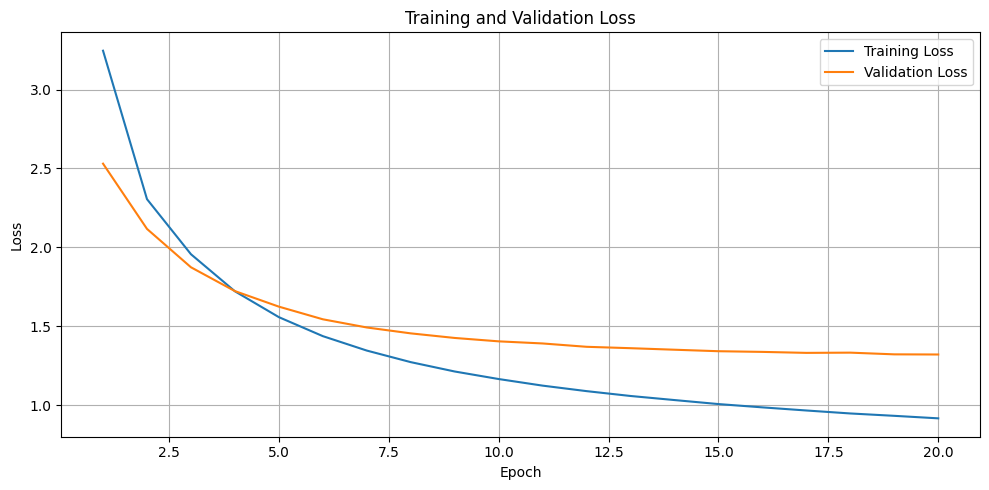

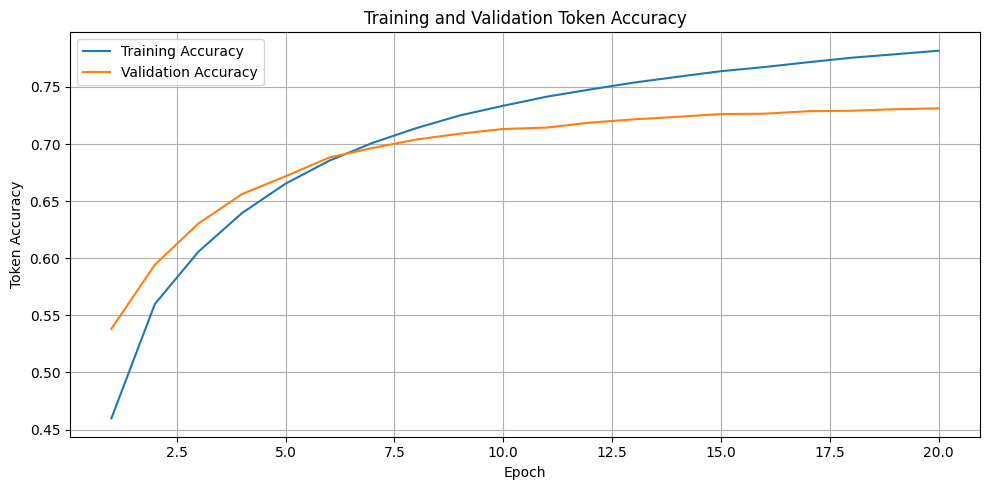

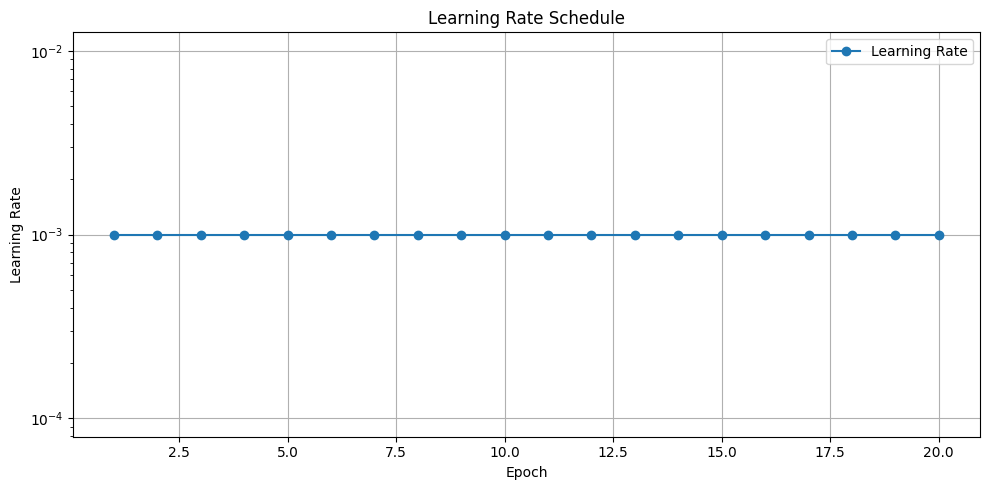

In [ ]:
plot_training_history(baseline_history)

## Baseline GRU Training Results (E0)

### 1. Training Performance

The baseline GRU model was trained for 20 epochs using one GRU layer in both the encoder and decoder. Training loss decreased from 3.2461 to 0.9174, while validation loss decreased from 2.5306 to 1.3218. Training token accuracy increased from 45.99% to 78.18%, and validation token accuracy reached 73.13%.

### 2. Learning Behavior

Both training and validation loss decreased throughout training, indicating that the model learned useful patterns from the English–French sentence pairs. However, after approximately epoch 10, validation loss improved more slowly while training loss continued to decrease. The widening gap suggests some overfitting.

Validation token accuracy also began to plateau in the later epochs, reaching 73.13% at epoch 20, compared with 78.18% training accuracy.

### 3. Learning-Rate Behavior

The learning rate remained at 0.001 throughout all 20 epochs. The `ReduceLROnPlateau` scheduler did not reduce it because the validation loss continued to improve.

### 4. Baseline Conclusion

The model learned successfully, but the difference between training and validation performance suggests that generalization could be improved. These results establish the reference point for subsequent architectural experiments.

The baseline will be compared with a two-layer GRU model and a model with larger embedding dimensions. Final translation quality must also be assessed using generated translations, since teacher-forced token accuracy alone does not measure complete translation quality.

## Experiment 2 (E1): GRU Depth

### Objective
Investigate whether increasing the depth of the GRU encoder and decoder improves English-to-French translation performance.

### Experimental Design
Both the encoder and decoder will use two GRU layers instead of one. The embedding dimension and hidden dimension will remain unchanged.

### Parameters
- Encoder GRU layers: 2
- Decoder GRU layers: 2
- English embedding dimension: 128
- French embedding dimension: 128
- Hidden dimension: 256
- Dropout rate: 0.2
- Batch size: 64
- Initial learning rate: 0.001
- Maximum epochs: 20

All other training settings, preprocessing steps, and dataset splits will remain the same as the baseline.

### Evaluation
Compare the best validation loss, validation token accuracy, training time, and number of trainable parameters against the baseline model (E0).

### Research Question
Does increasing GRU depth improve generalization, or does the additional model complexity increase training cost without a meaningful improvement in validation performance?

In [ ]:
# Baseline GRU model parameters
EMBEDDING_DIM = 128
HIDDEN_DIM = 256
NUM_LAYERS = 2
DROPOUT_RATE = 0.2

# Training parameters
BATCH_SIZE = 64
NUM_EPOCHS = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
GRADIENT_CLIP = 1.0

# Learning-rate scheduler parameters
SCHEDULER_FACTOR = 0.8
SCHEDULER_PATIENCE = 3
MIN_LEARNING_RATE = 1e-6

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")

Device: cuda


In [ ]:
encoder = Encoder(
    vocab_size=EN_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=EN_PAD_ID,
)

decoder = Decoder(
    vocab_size=FR_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=FR_PAD_ID
)

model = Seq2Seq(
    encoder=encoder,
    decoder=decoder
).to(device=device)

In [ ]:
criterion = nn.CrossEntropyLoss(
    ignore_index=FR_PAD_ID,
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=SCHEDULER_FACTOR,
    patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LEARNING_RATE,
)

In [ ]:
history_e1 = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    scheduler=scheduler,
    num_epochs=NUM_EPOCHS,
    en_pad_id=EN_PAD_ID,
    fr_pad_id=FR_PAD_ID,
    device=device,
)


Epoch [1/20] Train Loss: 2.8559 | Val Loss: 2.1914 | Train Acc: 50.80% | Val Acc: 58.95% | LR: 0.001
Epoch [2/20] Train Loss: 1.9331 | Val Loss: 1.7283 | Train Acc: 62.07% | Val Acc: 66.14% | LR: 0.001
Epoch [3/20] Train Loss: 1.5415 | Val Loss: 1.5102 | Train Acc: 67.85% | Val Acc: 69.62% | LR: 0.001
Epoch [4/20] Train Loss: 1.3177 | Val Loss: 1.3937 | Train Acc: 71.39% | Val Acc: 71.67% | LR: 0.001
Epoch [5/20] Train Loss: 1.1746 | Val Loss: 1.3236 | Train Acc: 73.78% | Val Acc: 72.86% | LR: 0.001
Epoch [6/20] Train Loss: 1.0708 | Val Loss: 1.2775 | Train Acc: 75.53% | Val Acc: 73.69% | LR: 0.001
Epoch [7/20] Train Loss: 0.9962 | Val Loss: 1.2478 | Train Acc: 76.84% | Val Acc: 74.18% | LR: 0.001
Epoch [8/20] Train Loss: 0.9357 | Val Loss: 1.2314 | Train Acc: 77.93% | Val Acc: 74.62% | LR: 0.001
Epoch [9/20] Train Loss: 0.8872 | Val Loss: 1.2154 | Train Acc: 78.89% | Val Acc: 74.89% | LR: 0.001
Epoch [10/20] Train Loss: 0.8474 | Val Loss: 1.2081 | Train Acc: 79.60% | Val Acc: 75.20% |

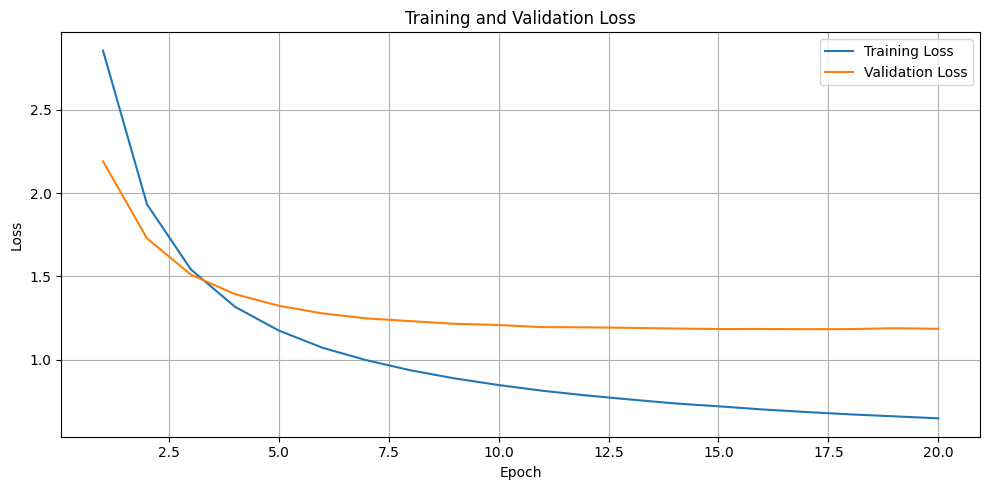

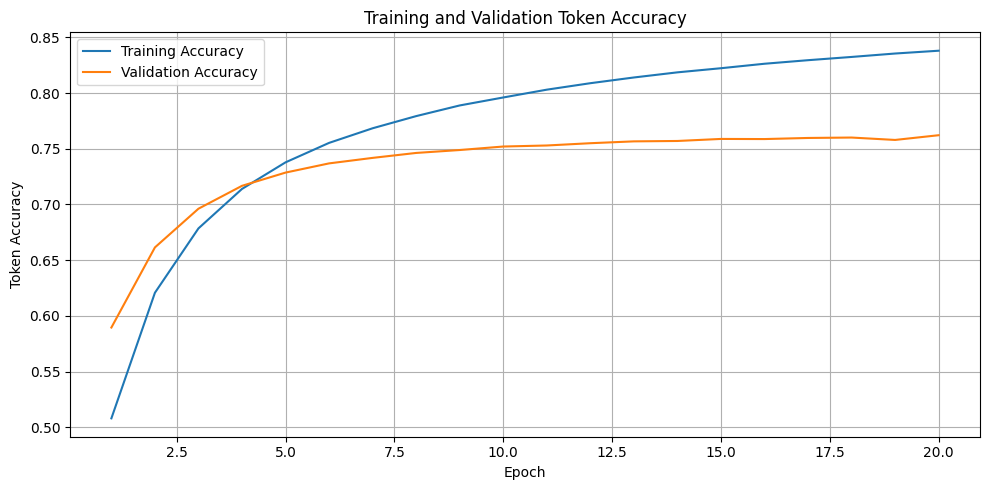

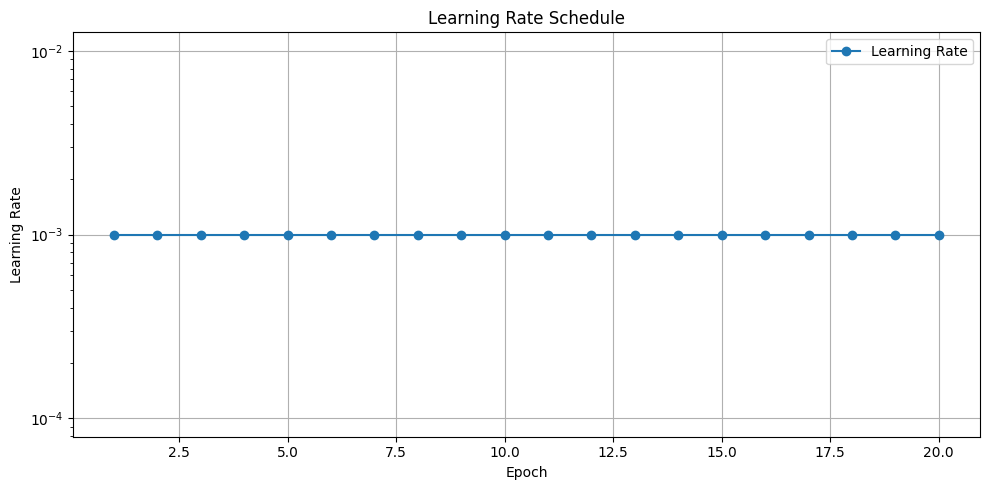

In [ ]:
plot_training_history(history_e1)

In [ ]:
test_results_e0 = evaluate_model(
    model=model,
    test_loader=test_loader,
    criterion=criterion,
    device=device,
    en_pad_id=EN_PAD_ID,
    fr_pad_id=FR_PAD_ID,
)

Test Loss: 1.1909
Test Token Accuracy: 76.09%


## Experiment 2 (E1): Two-Layer GRU Results

### 1. Training Performance

The encoder and decoder were increased from one GRU layer to two, while the embedding dimension remained 128 and the hidden dimension remained 256.

After 20 epochs, training loss reached 0.6474, while validation loss reached 1.1852. Training token accuracy was 83.80%, and validation token accuracy was 76.21%.

### 2. Learning Behavior

Training and validation loss decreased throughout most of training. However, training loss continued to decrease more rapidly than validation loss, and the gap between training and validation accuracy widened. This suggests some overfitting.

The best validation loss was 1.1830 at epoch 17, while the highest validation token accuracy was 76.21% at epoch 20.

### 3. Learning-Rate Behavior

The learning rate remained at 0.001 throughout training because validation loss continued to improve sufficiently for the scheduler not to reduce it.

### 4. Conclusion

The two-layer GRU achieved better validation performance than the one-layer baseline. Validation loss decreased from 1.3218 to 1.1830, and the best validation token accuracy improved from 73.13% to 76.21%.

These results suggest that increasing recurrent depth helped the model learn more useful representations. However, the additional model complexity also increased the training–validation performance gap. The experiment should be evaluated on the held-out test set before drawing conclusions about generalization.

## Experiment 3 (E2): Increasing Embedding Dimension

### Objective
Investigate whether increasing the embedding dimension improves English-to-French translation performance while keeping the GRU architecture unchanged.

### Experimental Design
Return to the one-layer baseline architecture and increase the embedding dimensions for both English and French from 128 to 256. Keep the hidden dimension fixed at 256.

### Parameters
- Encoder GRU layers: 1
- Decoder GRU layers: 1
- English embedding dimension: 256
- French embedding dimension: 256
- Hidden dimension: 256
- Dropout rate: 0.2
- Batch size: 64
- Initial learning rate: 0.001
- Maximum epochs: 20

All other training settings, preprocessing steps, and dataset splits will remain unchanged.

### Evaluation
Compare the best validation loss, validation token accuracy, training time, and number of trainable parameters against the baseline (E0).

### Research Question
Does increasing the embedding dimension improve validation performance, or does the additional parameter cost provide limited benefit?

In [ ]:
# Baseline GRU model parameters
EMBEDDING_DIM = 256
HIDDEN_DIM = 256
NUM_LAYERS = 1
DROPOUT_RATE = 0.2

# Training parameters
BATCH_SIZE = 64
NUM_EPOCHS = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
GRADIENT_CLIP = 1.0

# Learning-rate scheduler parameters
SCHEDULER_FACTOR = 0.8
SCHEDULER_PATIENCE = 3
MIN_LEARNING_RATE = 1e-6

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")

Device: cuda


In [ ]:
encoder = Encoder(
    vocab_size=EN_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=EN_PAD_ID,
)

decoder = Decoder(
    vocab_size=FR_VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    padding_idx=FR_PAD_ID
)

model = Seq2Seq(
    encoder=encoder,
    decoder=decoder
).to(device=device)

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=SCHEDULER_FACTOR,
    patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LEARNING_RATE,
)

criterion = nn.CrossEntropyLoss(
    ignore_index=FR_PAD_ID,
)

In [55]:
history_e2 = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    scheduler=scheduler,
    num_epochs=NUM_EPOCHS,
    en_pad_id = EN_PAD_ID,
    fr_pad_id = FR_PAD_ID,
    device=device,
)

Epoch [1/20] Train Loss: 0.8328 | Val Loss: 1.2744 | Train Acc: 79.96% | Val Acc: 74.01% | LR: 0.001
Epoch [2/20] Train Loss: 0.8246 | Val Loss: 1.2750 | Train Acc: 80.13% | Val Acc: 74.15% | LR: 0.001
Epoch [3/20] Train Loss: 0.8140 | Val Loss: 1.2741 | Train Acc: 80.38% | Val Acc: 74.18% | LR: 0.001
Epoch [4/20] Train Loss: 0.8053 | Val Loss: 1.2719 | Train Acc: 80.53% | Val Acc: 74.21% | LR: 0.001
Epoch [5/20] Train Loss: 0.7976 | Val Loss: 1.2719 | Train Acc: 80.70% | Val Acc: 74.35% | LR: 0.001
Epoch [6/20] Train Loss: 0.7879 | Val Loss: 1.2769 | Train Acc: 80.95% | Val Acc: 74.21% | LR: 0.001
Epoch [7/20] Train Loss: 0.7815 | Val Loss: 1.2762 | Train Acc: 81.04% | Val Acc: 74.26% | LR: 0.001
Epoch [8/20] Train Loss: 0.7762 | Val Loss: 1.2750 | Train Acc: 81.17% | Val Acc: 74.30% | LR: 0.0008
Epoch [9/20] Train Loss: 0.7166 | Val Loss: 1.2559 | Train Acc: 82.51% | Val Acc: 74.77% | LR: 0.0008
Epoch [10/20] Train Loss: 0.6995 | Val Loss: 1.2623 | Train Acc: 82.91% | Val Acc: 74.77%

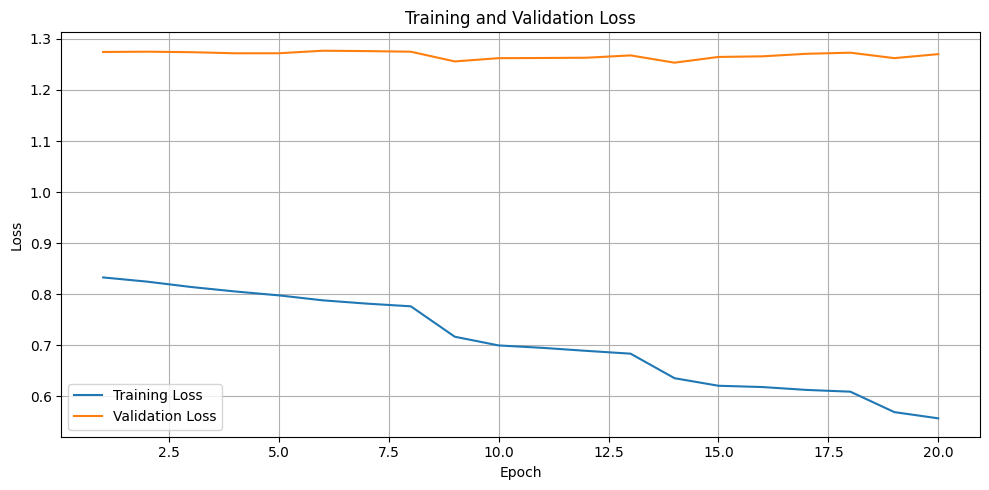

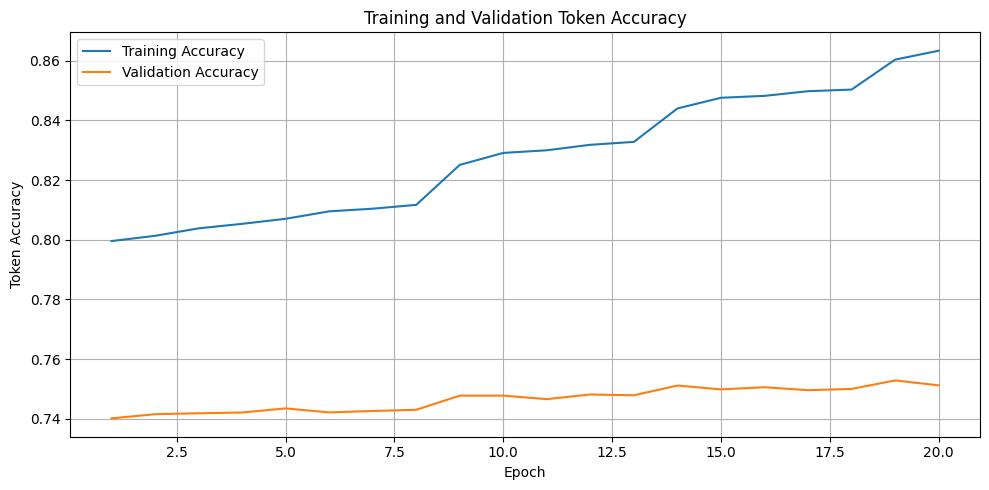

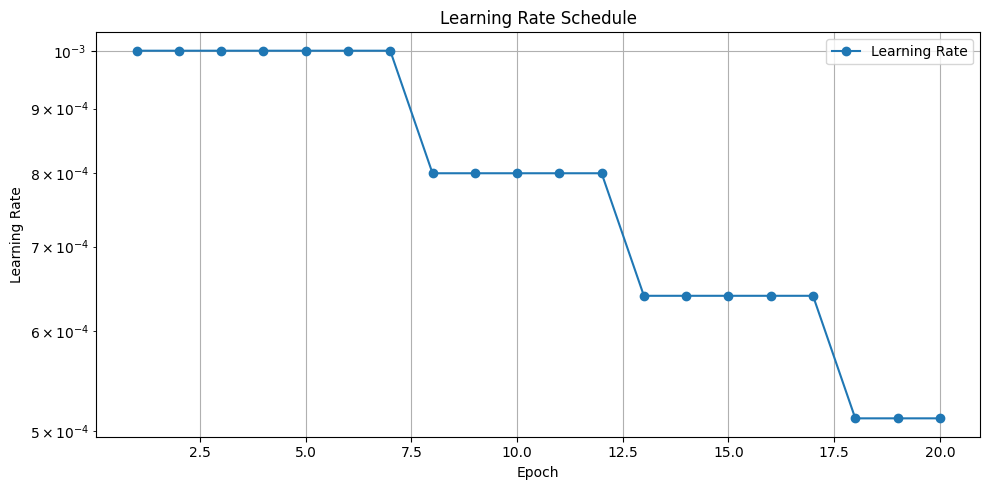

In [56]:
plot_training_history(history_e2)

In [59]:
test_results_e1 = evaluate_model(
    model=model,
    test_loader=test_loader,
    criterion=criterion,
    device=device,
    en_pad_id=EN_PAD_ID,
    fr_pad_id=FR_PAD_ID,

)

Test Loss: 1.2842
Test Token Accuracy: 75.01%


## Experiment E2: GRU Embedding Dimension Experiment

### 1. Objective

The objective of Experiment E2 was to investigate the effect of increasing the embedding dimension on English–French machine translation performance, building on the baseline experiment (E0) and the depth experiment (E1).

### 2. Experimental Setup

The experiment retained the GRU encoder–decoder architecture and the same dataset, preprocessing pipeline, train/validation/test splits, and shared training utilities used in the previous experiments.

The configuration for E2 was:

- **Embedding dimension:** 256
- **Hidden dimension:** 256
- **Number of recurrent layers:** 1
- **Batch size:** 64
- **Optimizer:** Adam
- **Initial learning rate:** 0.001
- **Weight decay:** 0.00001
- **Loss function:** Cross-entropy loss, ignoring French padding tokens
- **Gradient clipping:** Maximum norm of 1.0
- **Learning-rate scheduler:** ReduceLROnPlateau
- **Maximum epochs:** 20
- **Dropout:** 0.2

The model was trained using teacher forcing. Token-level loss and accuracy were calculated while excluding padded target positions.

### 3. Training Interruption

The training session was interrupted by a runtime disconnection. Training was subsequently restarted, which introduced discontinuities in the recorded training accuracy and learning-rate history.

Consequently, the plotted history should not be interpreted as a fully continuous training trajectory without accounting for the interruption. The learning-rate changes and accuracy jumps are documented as artifacts of the interrupted session rather than attributed solely to changes in model learning.

### 4. Results

The reported final metrics were:

| Metric | Result |
|---|---:|
| Training loss | 0.5567 |
| Validation loss | 1.2702 |
| Training token accuracy | 86.34% |
| Validation token accuracy | 75.12% |
| Test loss | 1.2842 |
| Test token accuracy | 75.01% |
| Final learning rate | 0.000512 |

### 5. Learning Curves

The training loss decreased throughout the recorded run, reaching 0.5567. Training token accuracy reached 86.34%.

Validation loss remained relatively stable and finished at 1.2702, while validation token accuracy reached 75.12%. The gap between training and validation performance indicates that the model fitted the training data better than it generalized to unseen validation examples.

The learning-rate scheduler reduced the learning rate from 0.001 to 0.0008, then to 0.00064, and subsequently to 0.000512.

The interruption must be considered when interpreting these curves because the recorded trajectory includes a restart.

### 6. Test Evaluation

The final reported test loss was 1.2842, with a token accuracy of 75.01%. The test accuracy was close to the validation accuracy of 75.12%, suggesting similar token-level performance on these two splits.

These metrics measure teacher-forced next-token prediction. They do not directly measure complete-sentence translation quality, so a separate inference evaluation would be needed to assess generated translations.

### 7. Conclusion

Experiment E2 completed the planned GRU experiment sequence following the baseline (E0) and depth experiment (E1). The model achieved 75.01% test token accuracy, with a test loss of 1.2842.

Although training performance improved substantially, validation loss remained comparatively high and validation accuracy improved only modestly. This indicates a generalization gap that should be considered when comparing the experiments.

The training interruption is an important reproducibility limitation. Future comparisons should use continuous training logs or explicitly combine the histories from each training segment, and should preserve the best validation checkpoint for final evaluation.

The next stage is the LSTM encoder–decoder experiment, using the same dataset, preprocessing, evaluation procedure, and shared training utilities. The experimental configuration will be defined before training so that the comparison with the GRU results remains consistent.


In [68]:
from getpass import getpass
import os
import subprocess
import tempfile

username = input("GitHub username: ").strip()
token = getpass("GitHub Personal Access Token: ")

# Temporary helper: supplies credentials only when Git requests them.
helper_code = """#!/bin/sh
case "$1" in
    *Username*) printf '%s\\n' "$GITHUB_USERNAME" ;;
    *Password*) printf '%s\\n' "$GITHUB_TOKEN" ;;
    *) exit 1 ;;
esac
"""

helper_path = None

try:
    with tempfile.NamedTemporaryFile(
        mode="w", suffix=".sh", delete=False
    ) as helper:
        helper.write(helper_code)
        helper_path = helper.name

    os.chmod(helper_path, 0o700)

    env = os.environ.copy()
    env["GITHUB_USERNAME"] = username
    env["GITHUB_TOKEN"] = token
    env["GIT_ASKPASS"] = helper_path
    env["GIT_TERMINAL_PROMPT"] = "0"

    result = subprocess.run(
        ["git", "push"],
        env=env,
        text=True,
        capture_output=True
    )

    print(result.stdout)
    if result.stderr:
        print(result.stderr)

    if result.returncode == 0:
        print("Push completed successfully.")
    else:
        print(f"Push failed with exit code {result.returncode}.")

finally:
    if helper_path and os.path.exists(helper_path):
        os.remove(helper_path)

    token = None
    if "GITHUB_TOKEN" in locals():
        del env["GITHUB_TOKEN"]

GitHub username: davidmba819
GitHub Personal Access Token: ··········

To https://github.com/davidmba819/english-french-machine-translation.git
   b70f5b9..a6a1c40  main -> main

Push completed successfully.


In [69]:
!git push

fatal: could not read Username for 'https://github.com': No such device or address
